# Olist Brazilian E-Commerce

Задача исследования - изучить структуру заказов электронной коммерции, качество связей между таблицами и возможность построить корректную обучающую выборку для прогноза задержки доставки. Целевая переменная в исходных данных отсутствует и формируется из фактической и обещанной дат доставки. Рассматривается бинарная классификация для заказов, завершившихся доставкой.

Источник: [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). Расчёты и выводы представлены в `EDA_olist_brazilian_ecommerce.md`.

Архив [archive.zip](https://drive.google.com/file/d/1MJsj4x5spwx-jnh2UXj9bi67FW2vlRDN/view?usp=drive_link) содержит девять CSV: `olist_orders_dataset.csv`, `olist_customers_dataset.csv`, `olist_order_items_dataset.csv`, `olist_order_payments_dataset.csv`, `olist_order_reviews_dataset.csv`, `olist_products_dataset.csv`, `olist_sellers_dataset.csv`, `olist_geolocation_dataset.csv`, `product_category_name_translation.csv`. Архив размещается рядом с ноутбуком. Ячейки выполняются последовательно сверху вниз.

## 1. Первичный анализ

Проверяются состав девяти исходных таблиц, типы признаков, пропуски и повторяющиеся строки.

In [2]:
from pathlib import Path
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

archive = Path("archive.zip")
if not archive.is_file():
    raise FileNotFoundError(f"Не найден архив: {archive.resolve()}")

file_names = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
with ZipFile(archive) as source:
    missing_files = [name for name in file_names.values() if name not in source.namelist()]
    if missing_files:
        raise FileNotFoundError(f"Внутри ZIP отсутствуют: {', '.join(missing_files)}")
    tables = {key: pd.read_csv(source.open(filename), low_memory=False)
              for key, filename in file_names.items()}

orders, customers, items = (tables[key] for key in ["orders", "customers", "items"])
payments, reviews, products = (tables[key] for key in ["payments", "reviews", "products"])
sellers, geolocation, translation = (tables[key] for key in ["sellers", "geolocation", "translation"])
print("Прочитано таблиц:", len(tables), "из архива", archive.name)

Прочитано таблиц: 9 из архива archive.zip


In [3]:
structure = pd.DataFrame([
    {"Таблица": file_names[name], "Строк": len(frame), "Столбцов": frame.shape[1],
     "Полных повторов": int(frame.duplicated().sum()),
     "Признаков с пропусками": int(frame.isna().any().sum())}
    for name, frame in tables.items()
])
display(structure.set_index("Таблица"))

,Строк,Столбцов,Полных повторов,Признаков с пропусками
Таблица,,,,
olist_orders_dataset.csv,99441,8,0,3
olist_customers_dataset.csv,99441,5,0,0
olist_order_items_dataset.csv,112650,7,0,0
olist_order_payments_dataset.csv,103886,5,0,0
olist_order_reviews_dataset.csv,99224,7,0,2
olist_products_dataset.csv,32951,9,0,8
olist_sellers_dataset.csv,3095,4,0,0
olist_geolocation_dataset.csv,1000163,5,261831,0
product_category_name_translation.csv,71,2,0,0


In [4]:
for name in ["orders", "items", "products", "reviews"]:
    print(f"{name}: типы столбцов")
    display(tables[name].dtypes.astype(str).value_counts().rename("Число столбцов").to_frame())

missing_rows = []
for name, frame in tables.items():
    for column, count in frame.isna().sum().items():
        if count:
            missing_rows.append({"Таблица": name, "Признак": column, "Пропусков": int(count),
                                 "Доля, %": round(100 * count / len(frame), 2)})
missing_summary = pd.DataFrame(missing_rows).sort_values(["Доля, %", "Пропусков"], ascending=False)
display(missing_summary.head(20))

orders: типы столбцов


,Число столбцов
str,8


items: типы столбцов


,Число столбцов
str,4
float64,2
int64,1


products: типы столбцов


,Число столбцов
float64,7
str,2


reviews: типы столбцов


,Число столбцов
str,6
int64,1


,Таблица,Признак,Пропусков,"Доля, %"
3,reviews,review_comment_title,87656,88.34
4,reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
1,orders,order_delivered_carrier_date,1783,1.79
0,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


## 2. Ключи таблиц и кратность соединений

Основная единица наблюдения - заказ (`order_id`). Проверяются уникальность первичных ключей, покрытие внешних ключей и случаи «один ко многим». Соединения нескольких дочерних таблиц без агрегации могут размножать заказы и суммы.

In [5]:
primary_keys = {"orders": "order_id", "customers": "customer_id", "products": "product_id",
                "sellers": "seller_id", "translation": "product_category_name"}
key_table = pd.DataFrame([
    {"Таблица": name, "Ключ": key, "Уникальных": int(tables[name][key].nunique()),
     "Повторных строк ключа": int(tables[name][key].duplicated().sum()),
     "Пропусков ключа": int(tables[name][key].isna().sum())}
    for name, key in primary_keys.items()
])
display(key_table)

,Таблица,Ключ,Уникальных,Повторных строк ключа,Пропусков ключа
0,orders,order_id,99441,0,0
1,customers,customer_id,99441,0,0
2,products,product_id,32951,0,0
3,sellers,seller_id,3095,0,0
4,translation,product_category_name,71,0,0


In [6]:
links = [
    ("orders → customers", orders, "customer_id", customers, "customer_id"),
    ("items → orders", items, "order_id", orders, "order_id"),
    ("items → products", items, "product_id", products, "product_id"),
    ("items → sellers", items, "seller_id", sellers, "seller_id"),
    ("payments → orders", payments, "order_id", orders, "order_id"),
    ("reviews → orders", reviews, "order_id", orders, "order_id"),
]
link_table = pd.DataFrame([
    {"Связь": name, "Несопоставленных строк": int((~left[lk].isin(right[rk])).sum())}
    for name, left, lk, right, rk in links
])
display(link_table)

multiplicity = []
for name, frame in [("items", items), ("payments", payments), ("reviews", reviews)]:
    group_sizes = frame.groupby("order_id").size()
    multiplicity.append({"Таблица": name,
                         "Заказов с несколькими строками": int(group_sizes.gt(1).sum()),
                         "Максимум строк на заказ": int(group_sizes.max()),
                         "Заказов без записей": int((~orders.order_id.isin(group_sizes.index)).sum())})
display(pd.DataFrame(multiplicity))

,Связь,Несопоставленных строк
0,orders → customers,0
1,items → orders,0
2,items → products,0
3,items → sellers,0
4,payments → orders,0
5,reviews → orders,0


,Таблица,Заказов с несколькими строками,Максимум строк на заказ,Заказов без записей
0,items,9803,21,775
1,payments,2961,29,1
2,reviews,547,3,768


In [7]:
naive_counts = pd.Series(1, index=orders.order_id.to_numpy(), dtype="int64")
for frame in [items, payments, reviews]:
    n_per_order = frame.groupby("order_id").size()
    naive_counts *= naive_counts.index.map(n_per_order).fillna(1).astype("int64").to_numpy()
naive_rows = int(naive_counts.sum())

payment_total = float(payments.payment_value.sum())
item_counts = items.groupby("order_id").size()
wrong_total = float((payments.payment_value *
                     payments.order_id.map(item_counts).fillna(1)).sum())
print("Заказов:", len(orders), "строк после наивных LEFT JOIN:", naive_rows)
print("Сумма платежей до соединения:", round(payment_total, 2))
print("Сумма после наивного JOIN с позициями:", round(wrong_total, 2))
print("Искажение суммы, %:", round(100 * (wrong_total / payment_total - 1), 2))

Заказов: 99441 строк после наивных LEFT JOIN: 119143
Сумма платежей до соединения: 16008872.12
Сумма после наивного JOIN с позициями: 20470726.66
Искажение суммы, %: 27.87


In [8]:
counts_per_customer = customers.customer_unique_id.value_counts()
print("Уникальных customer_unique_id:", counts_per_customer.size)
print("Покупателей с несколькими заказами:", int(counts_per_customer.gt(1).sum()))
print("Максимум заказов одного покупателя:", int(counts_per_customer.max()))
print("Заказов с несколькими продавцами:", int(items.groupby("order_id").seller_id.nunique().gt(1).sum()))

Уникальных customer_unique_id: 96096
Покупателей с несколькими заказами: 2997
Максимум заказов одного покупателя: 17
Заказов с несколькими продавцами: 1278


## 3. Формирование целевой переменной

Для сценария прогноза просрочки целевая переменная равна 1, если календарная дата фактического получения позже обещанной даты. Время суток не сравнивается: в источнике обещанная дата записана как полночь. Для расчёта известной метки рассматриваются только заказы со статусом `delivered` и обеими датами доставки. Не завершённые заказы не приравниваются к своевременно доставленным.

In [9]:
order_date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                   "order_delivered_customer_date", "order_estimated_delivery_date"]
for name in order_date_cols:
    orders[name] = pd.to_datetime(orders[name], errors="coerce")
for name in ["review_creation_date", "review_answer_timestamp"]:
    reviews[name] = pd.to_datetime(reviews[name], errors="coerce")
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"], errors="coerce")

print("Статусы заказов:")
display(orders.order_status.value_counts().rename_axis("Статус").to_frame("Заказов"))
print("Отсутствуют фактические даты доставки:", int(orders.order_delivered_customer_date.isna().sum()))

Статусы заказов:


,Заказов
Статус,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Отсутствуют фактические даты доставки: 2965


In [10]:
known_target = (orders.order_status.eq("delivered") &
                orders.order_delivered_customer_date.notna() &
                orders.order_estimated_delivery_date.notna())
labelled = orders.loc[known_target].copy()
labelled["late_delivery"] = (
    labelled.order_delivered_customer_date.dt.normalize() >
    labelled.order_estimated_delivery_date.dt.normalize()
).astype("int8")

late_timestamp = int((labelled.order_delivered_customer_date >
                      labelled.order_estimated_delivery_date).sum())
print("Заказов с известной меткой:", len(labelled))
print("Просроченных по календарной дате:", int(labelled.late_delivery.sum()),
      f"({100 * labelled.late_delivery.mean():.2f}%)")
print("Просроченных по точным timestamp:", late_timestamp)
print("Заказов, исключённых из постановки:", len(orders) - len(labelled))
print("Классы:")
display(labelled.late_delivery.value_counts().sort_index().rename_axis("late_delivery").to_frame("Заказов"))

Заказов с известной меткой: 96470
Просроченных по календарной дате: 6534 (6.77%)
Просроченных по точным timestamp: 7826
Заказов, исключённых из постановки: 2971
Классы:


,Заказов
late_delivery,
0,89936
1,6534


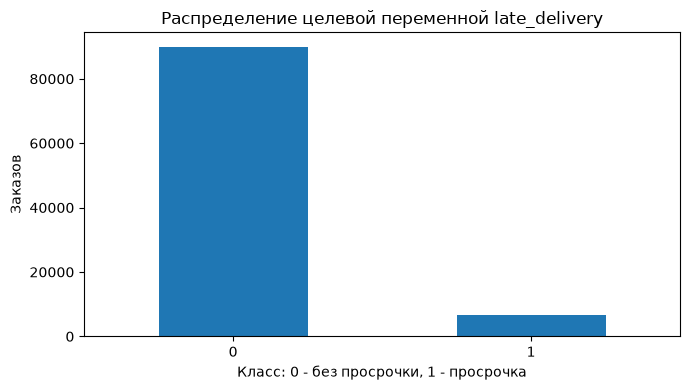

In [11]:
class_counts = labelled.late_delivery.value_counts().sort_index()
class_counts.plot.bar(figsize=(7, 4), rot=0)
plt.title("Распределение целевой переменной late_delivery")
plt.xlabel("Класс: 0 - без просрочки, 1 - просрочка")
plt.ylabel("Заказов")
plt.tight_layout()
plt.show()

## 4. Временная согласованность и неизвестные исходы

Сравниваются даты покупки, передачи перевозчику и доставки клиенту. Отдельно учитываются случаи, когда целевая переменная неизвестна: это не отрицательный класс. Выявленные нарушения порядка дат не исправляются без проверки первоисточника.

In [12]:
checks = {
    "Дата передачи перевозчику раньше покупки":
        orders.order_delivered_carrier_date < orders.order_purchase_timestamp,
    "Доставка клиенту раньше передачи перевозчику":
        orders.order_delivered_customer_date < orders.order_delivered_carrier_date,
    "Доставка клиенту раньше покупки":
        orders.order_delivered_customer_date < orders.order_purchase_timestamp,
    "Обещанная дата раньше покупки":
        orders.order_estimated_delivery_date < orders.order_purchase_timestamp,
}
display(pd.DataFrame({"Проверка": list(checks),
                      "Нарушений": [int(flag.sum()) for flag in checks.values()]}))
print("Диапазон дат покупки:", orders.order_purchase_timestamp.min(),
      "—", orders.order_purchase_timestamp.max())
print("Пропуски дат:")
display(orders[order_date_cols].isna().sum().rename("Пропусков").to_frame())

,Проверка,Нарушений
0,Дата передачи перевозчику раньше покупки,166
1,Доставка клиенту раньше передачи перевозчику,23
2,Доставка клиенту раньше покупки,0
3,Обещанная дата раньше покупки,0


Диапазон дат покупки: 2016-09-04 21:15:19 — 2018-10-17 17:30:18
Пропуски дат:


,Пропусков
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [13]:
unknown_outcomes = orders.loc[~known_target].order_status.value_counts()
print("Статусы заказов без известной целевой метки:")
display(unknown_outcomes.rename_axis("Статус").to_frame("Заказов"))

reviews_merged = reviews[["order_id", "review_creation_date"]].merge(
    orders[["order_id", "order_purchase_timestamp", "order_delivered_customer_date"]],
    on="order_id", how="left", validate="many_to_one")
print("Отзыв создан до даты покупки:",
      int((reviews_merged.review_creation_date < reviews_merged.order_purchase_timestamp).sum()))
print("Отзыв создан до фактической доставки:",
      int((reviews_merged.review_creation_date < reviews_merged.order_delivered_customer_date).sum()))

Статусы заказов без известной целевой метки:


,Заказов
Статус,
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


Отзыв создан до даты покупки: 74
Отзыв создан до фактической доставки: 8320


## 5. Товары, платежи и отзывы

Проверяются пропуски и крайние значения товарных атрибутов, особенности платежей и отзывов. Эти таблицы нельзя автоматически использовать как признаки прогноза на момент покупки: часть полей формируется после события или не имеет подтверждённого времени доступности.

In [14]:
print("Пропуски в products:")
display(products.isna().sum().loc[lambda x: x.gt(0)].rename("Пропусков").to_frame())
missing_translation = (products.product_category_name.notna() &
                       ~products.product_category_name.isin(translation.product_category_name))
print("Категорий в products:", products.product_category_name.nunique())
print("Товаров без категории:", int(products.product_category_name.isna().sum()))
print("Товаров с категорией без перевода:", int(missing_translation.sum()))
display(products.loc[missing_translation, "product_category_name"].value_counts().to_frame("Товаров"))

numeric_product_cols = ["product_weight_g", "product_length_cm", "product_height_cm",
                        "product_width_cm", "product_photos_qty"]
display(products[numeric_product_cols].describe(percentiles=[.5, .95, .99]).T)

Пропуски в products:


,Пропусков
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


Категорий в products: 73
Товаров без категории: 610
Товаров с категорией без перевода: 13


,Товаров
product_category_name,
portateis_cozinha_e_preparadores_de_alimentos,10
pc_gamer,3


,count,mean,std,min,50%,95%,99%,max
product_weight_g,32949.0,2276.472488,4282.038731,0.0,700.0,10850.0,22538.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,25.0,65.0,100.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,13.0,44.0,69.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,20.0,47.0,63.0,118.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,6.0,8.0,20.0


In [15]:
print("Виды оплаты:")
display(payments.payment_type.value_counts().rename_axis("Тип").to_frame("Транзакций"))
print("Нулевые суммы платежей:", int(payments.payment_value.eq(0).sum()))
print("Медиана суммы платежа:", payments.payment_value.median())
print("Максимальная сумма одной записи:", payments.payment_value.max())
print("Оценки отзывов:")
display(reviews.review_score.value_counts().sort_index().rename_axis("Оценка").to_frame("Отзывов"))
print("Пропуски текста отзывов, %:", round(100 * reviews.review_comment_message.isna().mean(), 2))
print("Пропуски заголовка отзывов, %:", round(100 * reviews.review_comment_title.isna().mean(), 2))
print("Заказов с несколькими разными оценками:",
      int(reviews.groupby("order_id").review_score.nunique().gt(1).sum()))

Виды оплаты:


,Транзакций
Тип,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


Нулевые суммы платежей: 9
Медиана суммы платежа: 100.0
Максимальная сумма одной записи: 13664.08
Оценки отзывов:


,Отзывов
Оценка,
1,11424
2,3151
3,8179
4,19142
5,57328


Пропуски текста отзывов, %: 58.7
Пропуски заголовка отзывов, %: 88.34
Заказов с несколькими разными оценками: 202


## 6. География и качество геолокации

Почтовый префикс имеет многократные координатные записи, поэтому прямое соединение с `geolocation` недопустимо. Проверяется полнота покрытия, число повторов и грубые географические выбросы. Координаты, выходящие за широкие границы Бразилии, рассматриваются как кандидаты на проверку, а не автоматически как ошибки.

In [16]:
geo_counts = geolocation.geolocation_zip_code_prefix.value_counts()
geo_stats = {
    "Строк геолокации": len(geolocation),
    "Уникальных префиксов": int(geo_counts.size),
    "Полных повторов строк": int(geolocation.duplicated().sum()),
    "Максимум записей одного префикса": int(geo_counts.max()),
    "Префиксов с несколькими штатами": int(geolocation.groupby("geolocation_zip_code_prefix").geolocation_state.nunique().gt(1).sum()),
    "Покупателей без координатного префикса": int((~customers.customer_zip_code_prefix.isin(geo_counts.index)).sum()),
    "Продавцов без координатного префикса": int((~sellers.seller_zip_code_prefix.isin(geo_counts.index)).sum()),
    "Широта вне [-34, 6]": int((~geolocation.geolocation_lat.between(-34, 6)).sum()),
    "Долгота вне [-74, -34]": int((~geolocation.geolocation_lng.between(-74, -34)).sum()),
    "Строк покупателей после наивного JOIN по ZIP": int(
        customers.customer_zip_code_prefix.map(geo_counts).fillna(1).sum()),
}
display(pd.Series(geo_stats, name="Значение").to_frame())

,Значение
Строк геолокации,1000163
Уникальных префиксов,19015
Полных повторов строк,261831
Максимум записей одного префикса,1146
Префиксов с несколькими штатами,8
Покупателей без координатного префикса,278
Продавцов без координатного префикса,7
"Широта вне [-34, 6]",31
"Долгота вне [-74, -34]",37
Строк покупателей после наивного JOIN по ZIP,15083733


In [17]:
# Медиана по уникальным допустимым координатам внутри каждого ZIP-префикса.
valid_geo = (geolocation.geolocation_lat.between(-34, 6) &
             geolocation.geolocation_lng.between(-74, -34))
geo_clean = geolocation.loc[valid_geo].drop_duplicates(
    subset=["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"])
geo_by_zip = geo_clean.groupby("geolocation_zip_code_prefix").agg(
    latitude=("geolocation_lat", "median"),
    longitude=("geolocation_lng", "median"),
    observations=("geolocation_lat", "size"))
print("Размер агрегированной географии:", geo_by_zip.shape)
print("Уникальных префиксов сохранено:", len(geo_by_zip))
print("Строк с исключёнными координатами:", int((~valid_geo).sum()))

Размер агрегированной географии: (19010, 3)
Уникальных префиксов сохранено: 19010
Строк с исключёнными координатами: 42


## 7. Различия риска просрочки между группами

Исследуется наблюдаемая доля `late_delivery` по географии, составу заказа и величине заказа. Это описательные зависимости; они не подтверждают причинное влияние и не заменяют проверку на отложенной выборке. Сначала создаются агрегаты позиций заказа, чтобы избежать размножения целевой переменной.

In [18]:
item_stats = items.groupby("order_id", sort=False).agg(
    n_items=("order_item_id", "size"),
    n_products=("product_id", "nunique"),
    n_sellers=("seller_id", "nunique"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"))

labelled_detail = labelled[["order_id", "customer_id", "order_purchase_timestamp", "late_delivery"]].merge(
    customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id", how="left", validate="one_to_one").merge(
    item_stats, left_on="order_id", right_index=True, how="left", validate="one_to_one")
print("Размеченных заказов после агрегации:", len(labelled_detail))
print("С отсутствующими позициями:", int(labelled_detail.n_items.isna().sum()))
print("Статистика заказа:")
display(labelled_detail[["n_items", "n_products", "n_sellers", "total_price", "total_freight"]].describe(percentiles=[.5, .9, .99]).T)

Размеченных заказов после агрегации: 96470
С отсутствующими позициями: 0
Статистика заказа:


,count,mean,std,min,50%,90%,99%,max
n_items,96470.0,1.142210,0.538824,1.00,1.00,1.000,3.0000,21.00
n_products,96470.0,1.038540,0.227951,1.00,1.00,1.000,2.0000,8.00
n_sellers,96470.0,1.013901,0.123542,1.00,1.00,1.000,2.0000,5.00
total_price,96470.0,137.040001,209.052608,0.85,86.50,269.000,990.0000,13440.00
total_freight,96470.0,22.785798,21.559959,0.00,17.17,39.381,104.2462,1794.96


In [19]:
by_state = labelled_detail.groupby("customer_state").agg(
    orders=("late_delivery", "size"), late=("late_delivery", "sum"))
by_state["late_pct"] = 100 * by_state.late / by_state.orders
print("Штаты с наибольшим числом заказов:")
display(by_state.sort_values("orders", ascending=False).head(12))

by_seller_n = labelled_detail.groupby("n_sellers").agg(
    orders=("late_delivery", "size"), late=("late_delivery", "sum"))
by_seller_n["late_pct"] = 100 * by_seller_n.late / by_seller_n.orders
print("Число продавцов в заказе:")
display(by_seller_n)

Штаты с наибольшим числом заказов:


,orders,late,late_pct
customer_state,,,
SP,40494,1820,4.494493
RJ,12350,1495,12.105263
MG,11354,519,4.571076
RS,5344,325,6.081587
PR,4923,199,4.042251
SC,3546,291,8.206430
BA,3256,396,12.162162
DF,2080,118,5.673077
ES,1995,214,10.726817


Число продавцов в заказе:


,orders,late,late_pct
n_sellers,,,
1,95195,6521,6.850150
2,1216,13,1.069079
3,54,0,0.000000
4,3,0,0.000000
5,2,0,0.000000


,orders,late_pct
price_bucket,,
"(0.849, 39.0]",19452,5.89
"(39.0, 67.9]",19178,6.56
"(67.9, 106.6]",19253,6.60
"(106.6, 175.0]",19298,7.33
"(175.0, 13440.0]",19289,7.49


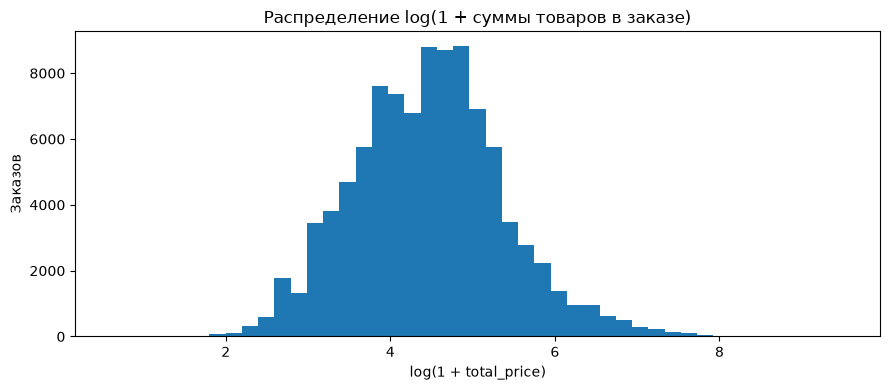

In [20]:
# Цена и доставка анализируются в полных заказах без размножения строк.
price_nonnull = labelled_detail.loc[labelled_detail.total_price.gt(0)].copy()
price_nonnull["price_bucket"] = pd.qcut(price_nonnull.total_price, q=5, duplicates="drop")
price_risk = price_nonnull.groupby("price_bucket", observed=True).agg(
    orders=("late_delivery", "size"), rate=("late_delivery", "mean"))
price_risk["late_pct"] = (100 * price_risk.rate).round(2)
display(price_risk[["orders", "late_pct"]])

plt.figure(figsize=(9, 4))
plt.hist(np.log1p(labelled_detail.total_price.dropna()), bins=45)
plt.title("Распределение log(1 + суммы товаров в заказе)")
plt.xlabel("log(1 + total_price)")
plt.ylabel("Заказов")
plt.tight_layout()
plt.show()

## 8. Временная структура и валидация

Для прогноза будущих заказов предлагается хронологический holdout. Простого разделения по дате покупки недостаточно: к моменту начала валидации часть старых доставок ещё не завершилась, поэтому их метки нельзя использовать при обучении. Дополнительно проверяется повторение реальных покупателей между частями.

На графике доли просрочек отдельно показаны месяцы как минимум со 100 наблюдениями; для единичных заказов месячная доля неустойчива.

Распределение просрочек по месяцам покупки:


,orders,late,late_pct
order_purchase_timestamp,,,
2016-09,1,1,100.000000
2016-10,265,2,0.754717
2016-12,1,0,0.000000
2017-01,750,22,2.933333
2017-02,1653,49,2.964307
2017-03,2546,116,4.556167
2017-04,2303,151,6.556665
2017-05,3545,106,2.990127
2017-06,3135,95,3.030303


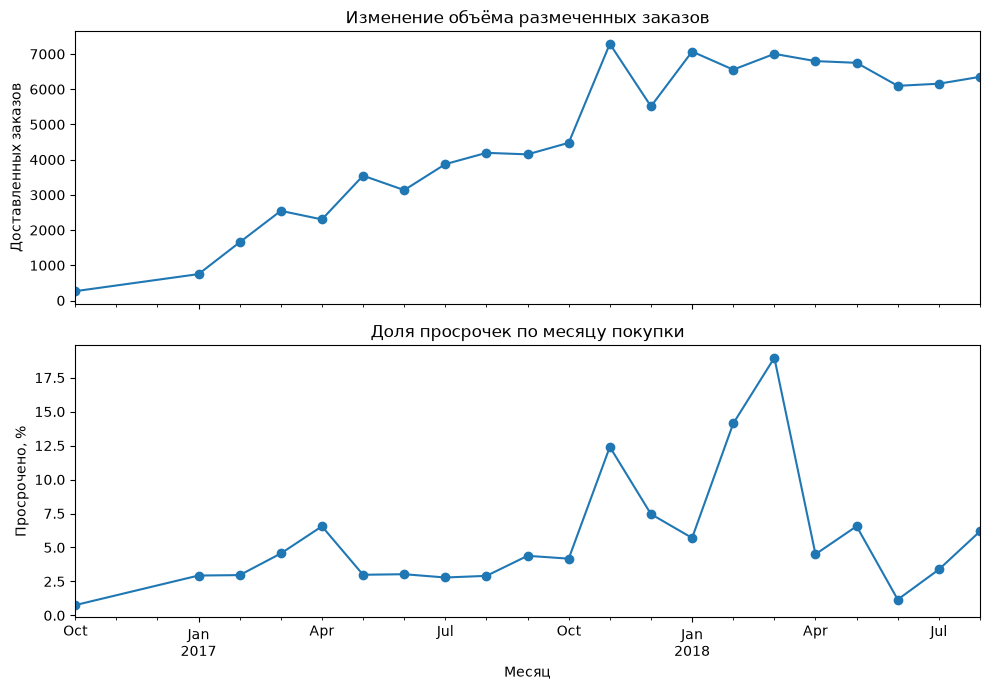

In [21]:
monthly = labelled_detail.groupby(
    labelled_detail.order_purchase_timestamp.dt.to_period("M")
).agg(orders=("late_delivery", "size"), late=("late_delivery", "sum"))
monthly["late_pct"] = 100 * monthly.late / monthly.orders
print("Распределение просрочек по месяцам покупки:")
display(monthly)

monthly_plot = monthly.loc[monthly.orders.ge(100)]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
monthly_plot["orders"].plot(ax=axes[0], marker="o")
axes[0].set_ylabel("Доставленных заказов")
axes[0].set_title("Изменение объёма размеченных заказов")
monthly_plot["late_pct"].plot(ax=axes[1], marker="o")
axes[1].set_ylabel("Просрочено, %")
axes[1].set_title("Доля просрочек по месяцу покупки")
axes[1].set_xlabel("Месяц")
plt.tight_layout()
plt.show()

In [22]:
ordered = labelled.sort_values(["order_purchase_timestamp", "order_id"])
cutoff = ordered.order_purchase_timestamp.iloc[int(0.8 * len(ordered))]
train_before = labelled.loc[labelled.order_purchase_timestamp < cutoff].copy()
validation = labelled.loc[labelled.order_purchase_timestamp >= cutoff].copy()
train_matured = train_before.loc[train_before.order_delivered_customer_date < cutoff].copy()

uids = orders[["order_id", "customer_id"]].merge(
    customers[["customer_id", "customer_unique_id"]], on="customer_id", validate="many_to_one")
train_uids = set(train_matured.order_id.map(uids.set_index("order_id").customer_unique_id))
val_uids = set(validation.order_id.map(uids.set_index("order_id").customer_unique_id))
validation_stats = pd.DataFrame([
    {"Часть": "Train по дате покупки", "Заказов": len(train_before),
     "Просрочено, %": round(100 * train_before.late_delivery.mean(), 2)},
    {"Часть": "Train с созревшими метками", "Заказов": len(train_matured),
     "Просрочено, %": round(100 * train_matured.late_delivery.mean(), 2)},
    {"Часть": "Validation", "Заказов": len(validation),
     "Просрочено, %": round(100 * validation.late_delivery.mean(), 2)},
])
print("Граница валидации:", cutoff)
print("Исключено из train из-за незавершённой к границе доставки:", len(train_before) - len(train_matured))
print("Общих customer_unique_id между train и validation:", len(train_uids & val_uids))
display(validation_stats)

Граница валидации: 2018-05-26 18:18:03
Исключено из train из-за незавершённой к границе доставки: 2048
Общих customer_unique_id между train и validation: 418


,Часть,Заказов,"Просрочено, %"
0,Train по дате покупки,77176,7.59
1,Train с созревшими метками,75128,7.11
2,Validation,19294,3.49


## 9. Формирование таблицы признаков для AutoML

Создаётся воспроизводимая витрина с одной строкой на заказ. Для базового сценария используются атрибуты покупателя и состава заказа, предположительно известные при оформлении: регион, товарные характеристики, продавцы, количество позиций, стоимость и географические координаты, агрегированные по почтовому префиксу. Исторические исходы доставки, `order_status`, подтверждение оплаты, отзывы и события перевозки исключаются из признаков. Доступность каталожных атрибутов, заявленной цены и стоимости доставки на момент заказа должна быть подтверждена при внедрении.

In [24]:
category_english = translation.set_index("product_category_name")["product_category_name_english"]
product_info = products[["product_id", "product_category_name", "product_weight_g",
                         "product_length_cm", "product_height_cm", "product_width_cm",
                         "product_photos_qty"]].copy()
product_info["volume_cm3"] = (
    product_info.product_length_cm * product_info.product_height_cm * product_info.product_width_cm)
product_info["category_label"] = product_info.product_category_name.map(category_english).fillna(
    product_info.product_category_name).fillna("unknown")

seller_info = sellers[["seller_id", "seller_state", "seller_zip_code_prefix"]].copy()
seller_info["seller_lat"] = seller_info.seller_zip_code_prefix.map(geo_by_zip.latitude)
seller_info["seller_lon"] = seller_info.seller_zip_code_prefix.map(geo_by_zip.longitude)

joined_items = (items.merge(product_info, on="product_id", how="left", validate="many_to_one")
                 .merge(seller_info, on="seller_id", how="left", validate="many_to_one"))

order_item_features = joined_items.groupby("order_id", sort=False).agg(
    n_items=("order_item_id", "size"), n_products=("product_id", "nunique"),
    n_sellers=("seller_id", "nunique"),
    n_categories=("product_category_name", "nunique"),
    total_price=("price", "sum"), total_freight=("freight_value", "sum"),
    mean_product_weight_g=("product_weight_g", "mean"),
    mean_product_volume_cm3=("volume_cm3", "mean"),
    mean_product_photos=("product_photos_qty", "mean"),
    first_category=("category_label", "first"),
    first_seller_state=("seller_state", "first"),
    distinct_seller_states=("seller_state", "nunique"),
    mean_seller_lat=("seller_lat", "mean"), mean_seller_lon=("seller_lon", "mean"))
order_item_features["category_summary"] = np.where(
    order_item_features.n_categories.gt(1), "multiple", order_item_features.first_category)
order_item_features["seller_state_summary"] = np.where(
    order_item_features.distinct_seller_states.gt(1), "multiple", order_item_features.first_seller_state)
order_item_features = order_item_features.drop(columns=["first_category", "first_seller_state"])

base = orders[["order_id", "customer_id", "order_purchase_timestamp"]].merge(
    customers[["customer_id", "customer_unique_id", "customer_state", "customer_zip_code_prefix"]],
    on="customer_id", how="left", validate="one_to_one")
base = base.merge(order_item_features, left_on="order_id", right_index=True,
                  how="left", validate="one_to_one")
base["customer_lat"] = base.customer_zip_code_prefix.map(geo_by_zip.latitude)
base["customer_lon"] = base.customer_zip_code_prefix.map(geo_by_zip.longitude)
base["purchase_month"] = base.order_purchase_timestamp.dt.month
base["purchase_weekday"] = base.order_purchase_timestamp.dt.day_of_week
base["purchase_hour"] = base.order_purchase_timestamp.dt.hour

feature_columns = ["customer_state", "customer_zip_code_prefix", "purchase_month", "purchase_weekday",
                   "purchase_hour", "n_items", "n_products", "n_sellers", "n_categories",
                   "total_price", "total_freight", "mean_product_weight_g",
                   "mean_product_volume_cm3", "mean_product_photos",
                   "category_summary", "seller_state_summary", "distinct_seller_states",
                   "customer_lat", "customer_lon", "mean_seller_lat", "mean_seller_lon"]
print("Строк в витрине:", len(base), "уникальных заказов:", base.order_id.nunique())
print("Заказов без позиций:", int(base.n_items.isna().sum()))
print("Число выбранных признаков:", len(feature_columns))

Строк в витрине: 99441 уникальных заказов: 99441
Заказов без позиций: 775
Число выбранных признаков: 21


In [25]:
# Для обучения используем только известные метки и признаки, существующие на дату покупки.
model_data = base.merge(labelled[["order_id", "late_delivery"]], on="order_id",
                        how="inner", validate="one_to_one")
train_ids = set(train_matured.order_id)
val_ids = set(validation.order_id)
model_train = model_data.loc[model_data.order_id.isin(train_ids), feature_columns + ["late_delivery"]].copy()
model_val = model_data.loc[model_data.order_id.isin(val_ids), feature_columns + ["late_delivery"]].copy()

print("Обучающих строк:", len(model_train), "проверочных:", len(model_val))
print("Пропуски в модельной выборке (первые 15 признаков):")
missing_for_model = model_data[feature_columns].isna().mean().mul(100).sort_values(ascending=False)
display(missing_for_model.head(15).round(2).rename("Пропуски, %").to_frame())
print("Проверка классов:")
display(pd.DataFrame({
    "train": model_train.late_delivery.value_counts().sort_index(),
    "validation": model_val.late_delivery.value_counts().sort_index()}).fillna(0).astype(int))

Обучающих строк: 75128 проверочных: 19294
Пропуски в модельной выборке (первые 15 признаков):


,"Пропуски, %"
mean_product_photos,1.38
customer_lat,0.27
customer_lon,0.27
mean_seller_lat,0.22
mean_seller_lon,0.22
mean_product_volume_cm3,0.02
mean_product_weight_g,0.02
purchase_hour,0.00
customer_zip_code_prefix,0.00
customer_state,0.00


Проверка классов:


,train,validation
late_delivery,,
0,69789,18620
1,5339,674


## 10. Выводы для конфигурации AutoML

- Исходные девять таблиц не образуют готовую обучающую матрицу. Для базового ML-сценария требуется отдельное формирование целевой переменной и агрегирование позиций заказа и координат по почтовому префиксу до уровня `order_id`.
- Прогноз после оформления заказа для доставленных заказов является задачей бинарной классификации с редким положительным классом. Не завершённые заказы нельзя автоматически считать своевременными; модель на доставленных заказах имеет ограниченную применимость ко всем будущим заказам.
- Для новых заказов необходим хронологический holdout с учётом созревания меток. Групповую оценку по `customer_unique_id` можно рассматривать отдельно, если бизнес-задача требует качества на новых покупателях.
- `order_delivered_customer_date`, `order_delivered_carrier_date`, итоговый `order_status` и отзывы нельзя включать в признаки на момент покупки. `order_estimated_delivery_date`, платежи и иные операционные поля допускаются только после проверки их реальной доступности в момент прогноза.
- В качестве проверок системы необходимы восстановление бизнес-цели, выбор метрики для редкого класса, обработка пропусков, контроль кратности JOIN, предотвращение утечек и валидация соответствующего типа.
- Витрина в разделе 9 является демонстрацией подготовки данных, а не результатом автоматической конфигурации AutoGluon. Для базового MVP её формирование должно быть отдельным воспроизводимым шагом перед передачей одной таблицы в AutoML.